# Case Study 19 — Testing a Campaign Across 40 Customer Segments

**The multiple-comparisons problem · family-wise error rate (FWER) and false discovery rate (FDR) · Bonferroni, Šidák,
Holm and Benjamini-Hochberg corrections · adjusted p-values and q-values · p-value histograms · the winner's curse
and regression to the mean · replication across waves · empirical-Bayes shrinkage · power per segment · exploratory vs
confirmatory analysis**

| | |
|---|---|
| **Domain** | Marketing: cross-sell SMS campaign |
| **Stakeholders** | Head of Cards Marketing, Campaign Analytics |
| **Difficulty** | Intermediate |
| **Importance** | 🟠 SHOULD GO THROUGH |
| **Builds on** | Case 03–04 (A/B tests, two-proportion tests), Case 14 (many groups) |
| **Data** | A randomised campaign test in 40 segments, two waves, about 258,000 customers |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`. A separate **answer key** (the true uplift of each segment) exists only
> because the data are simulated; the notebook opens it **only in Section 11**.

**What you will learn**

1. Why running 40 tests at α = 0.05 almost guarantees "winners" even if the campaign does nothing.
2. The difference between controlling the **chance of any false alarm** (FWER) and the **share of false alarms among
   the discoveries** (FDR), and which correction to use when.
3. Why the "winning" segments' estimated effects are **inflated** (winner's curse), and how a second wave or shrinkage
   shows it.
4. How to present a segment list honestly: **confirmed**, **promising** and **not supported**.

## Section 1 — Business context

You are a data scientist in **Campaign Analytics**. Marketing ran a cross-sell SMS campaign as a **randomised test**:
within each of **40 customer segments** (8 customer types × 5 regions), half the customers received the SMS
(**treatment**) and half did not (**control**). The campaign ran in **two waves** of two weeks. The outcome is
**conversion** (taking up the cross-sold product within 30 days).

The Head of Cards Marketing writes:

> *"I've circled every segment where the uplift is significant at 5%. There are seven 'winning' segments. I want the
> campaign focused on these next quarter and the other 31 dropped. Our analyst says there's something called a
> multiple-testing problem. Does it matter? How many of these winners are real?"*

## Section 2 — Business questions

1. Which segments show an uplift, and how large?
2. How many of the "significant" segments could be false alarms?
3. Which segments can we be confident about, and which are only promising?
4. Is the size of the winning uplifts reliable?
5. What should Marketing do next quarter?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Which segments respond? | 40 two-proportion tests | z-tests, uplift CIs |
| 2 | False alarms? | What happens to the error rates when 40 tests are run? | Simulation of a world with no effect; FWER and FDR |
| 3 | Confident vs promising | Corrected p-values | Bonferroni, Holm (FWER); Benjamini-Hochberg (FDR) |
| 4 | Reliable size? | Do estimated uplifts of selected segments hold up in fresh data? | Wave 1 vs wave 2; empirical-Bayes shrinkage |
| 5 | Next quarter | A decision rule that separates evidence from hope | Tiered list + confirmation test |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multitest import multipletests

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "19_multiple_testing_segments"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(1919)
pctfmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
ALPHA = 0.05

def two_prop(x1, n1, x0, n0):
    # Pooled two-proportion z-test (vectorised) and Wald CI for the difference (treatment − control).
    x1, n1, x0, n0 = map(lambda v: np.asarray(v, dtype=float), (x1, n1, x0, n0))
    p1, p0 = x1 / n1, x0 / n0
    pbar = (x1 + x0) / (n1 + n0)
    z = (p1 - p0) / np.sqrt(pbar * (1 - pbar) * (1 / n1 + 1 / n0))
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    return {"p_treat": p1, "p_ctrl": p0, "diff": p1 - p0, "se": se, "z": z, "p_value": 2 * stats.norm.sf(np.abs(z))}

## Section 4 — Load the data

In [2]:
raw = pd.read_csv(PATHS["data"] / "campaign_results.csv")
print(f"{len(raw)} rows = {raw['segment_id'].nunique()} segments × {raw['wave'].nunique()} waves × {raw['arm'].nunique()} arms;  missing: {raw.isna().sum().sum()}")
display(raw.head(6))
arms = raw.groupby("arm")[["customers", "conversions"]].sum()
arms["conversion rate"] = arms["conversions"] / arms["customers"]
display(arms)
bal = raw.pivot_table(index="segment_id", columns="arm", values="customers", aggfunc="sum")
print(f"Randomisation check: treatment ÷ control customers per segment ranges {(bal['treatment'] / bal['control']).min():.3f}–{(bal['treatment'] / bal['control']).max():.3f}")
seg_info = raw.drop_duplicates("segment_id").set_index("segment_id")[["customer_type", "region"]]

160 rows = 40 segments × 2 waves × 2 arms;  missing: 0


,segment_id,customer_type,region,wave,arm,customers,conversions
0,S01,Salaried (mass),North,1,control,808,41
1,S01,Salaried (mass),North,1,treatment,808,26
2,S01,Salaried (mass),North,2,control,803,26
3,S01,Salaried (mass),North,2,treatment,803,41
4,S02,Salaried (mass),South,1,control,687,31
5,S02,Salaried (mass),South,1,treatment,687,34


,customers,conversions,conversion rate
arm,,,
control,119037,6334,0.0532
treatment,119037,6599,0.0554


Randomisation check: treatment ÷ control customers per segment ranges 1.000–1.000


Customers were assigned to treatment or control **at random within each segment** (the treatment and control group
sizes are essentially equal everywhere), so a difference in conversion between the arms is a **causal** effect of
the SMS for that segment (Case 04), apart from chance.

## Section 5 — Segment-by-segment results

In [3]:
def seg_table(df):
    g = df.groupby(["segment_id", "arm"])[["customers", "conversions"]].sum().unstack("arm")
    t = two_prop(g[("conversions", "treatment")], g[("customers", "treatment")], g[("conversions", "control")], g[("customers", "control")])
    out = pd.DataFrame({"customers per arm": (g[("customers", "treatment")] + g[("customers", "control")]) / 2,
                        "control rate": t["p_ctrl"], "treatment rate": t["p_treat"], "uplift (pp)": 100 * t["diff"],
                        "ci_low (pp)": 100 * (t["diff"] - 1.96 * t["se"]), "ci_high (pp)": 100 * (t["diff"] + 1.96 * t["se"]),
                        "se (pp)": 100 * t["se"], "z": t["z"], "p_value": t["p_value"]}, index=g.index)
    return out.join(seg_info)

res = seg_table(raw)
res["significant at 5%"] = res["p_value"] < ALPHA
res = res.sort_values("p_value")
save_table(res, "segment_results", PATHS["tables"])
print(f"Segments with p < 0.05: {int(res['significant at 5%'].sum())} of {len(res)}   (marketing's 'winners')")
display(res[res["significant at 5%"]][["customer_type", "region", "control rate", "uplift (pp)", "ci_low (pp)", "ci_high (pp)", "p_value"]])
tot = raw.groupby("arm")[["customers", "conversions"]].sum()
overall = two_prop(tot.loc["treatment", "conversions"], tot.loc["treatment", "customers"], tot.loc["control", "conversions"], tot.loc["control", "customers"])
print(f"Overall (all 40 segments pooled, ONE test): uplift {100 * overall['diff']:+.2f} pp (95% CI {100 * (overall['diff'] - 1.96 * overall['se']):+.2f} to "
      f"{100 * (overall['diff'] + 1.96 * overall['se']):+.2f}), p = {fmt_p(float(overall['p_value']))}")

Segments with p < 0.05: 7 of 40   (marketing's 'winners')


,customer_type,region,control rate,uplift (pp),ci_low (pp),ci_high (pp),p_value
segment_id,,,,,,,
S13,Self-employed,East,0.0216,2.2765,1.5160,3.0370,0.0000
S22,Student,South,0.0823,2.3304,0.9425,3.7183,0.0010
S24,Student,West,0.0422,2.2289,0.7024,3.7554,0.0043
S31,Homemaker,North,0.0669,1.8662,0.4868,3.2456,0.0080
S29,Retired,West,0.0420,2.0396,0.5081,3.5711,0.0091
S36,Business owner,North,0.0411,1.6792,0.4163,2.9420,0.0092
S32,Homemaker,South,0.0645,2.0906,0.3336,3.8476,0.0198


Overall (all 40 segments pooled, ONE test): uplift +0.22 pp (95% CI +0.04 to +0.40), p = 0.017


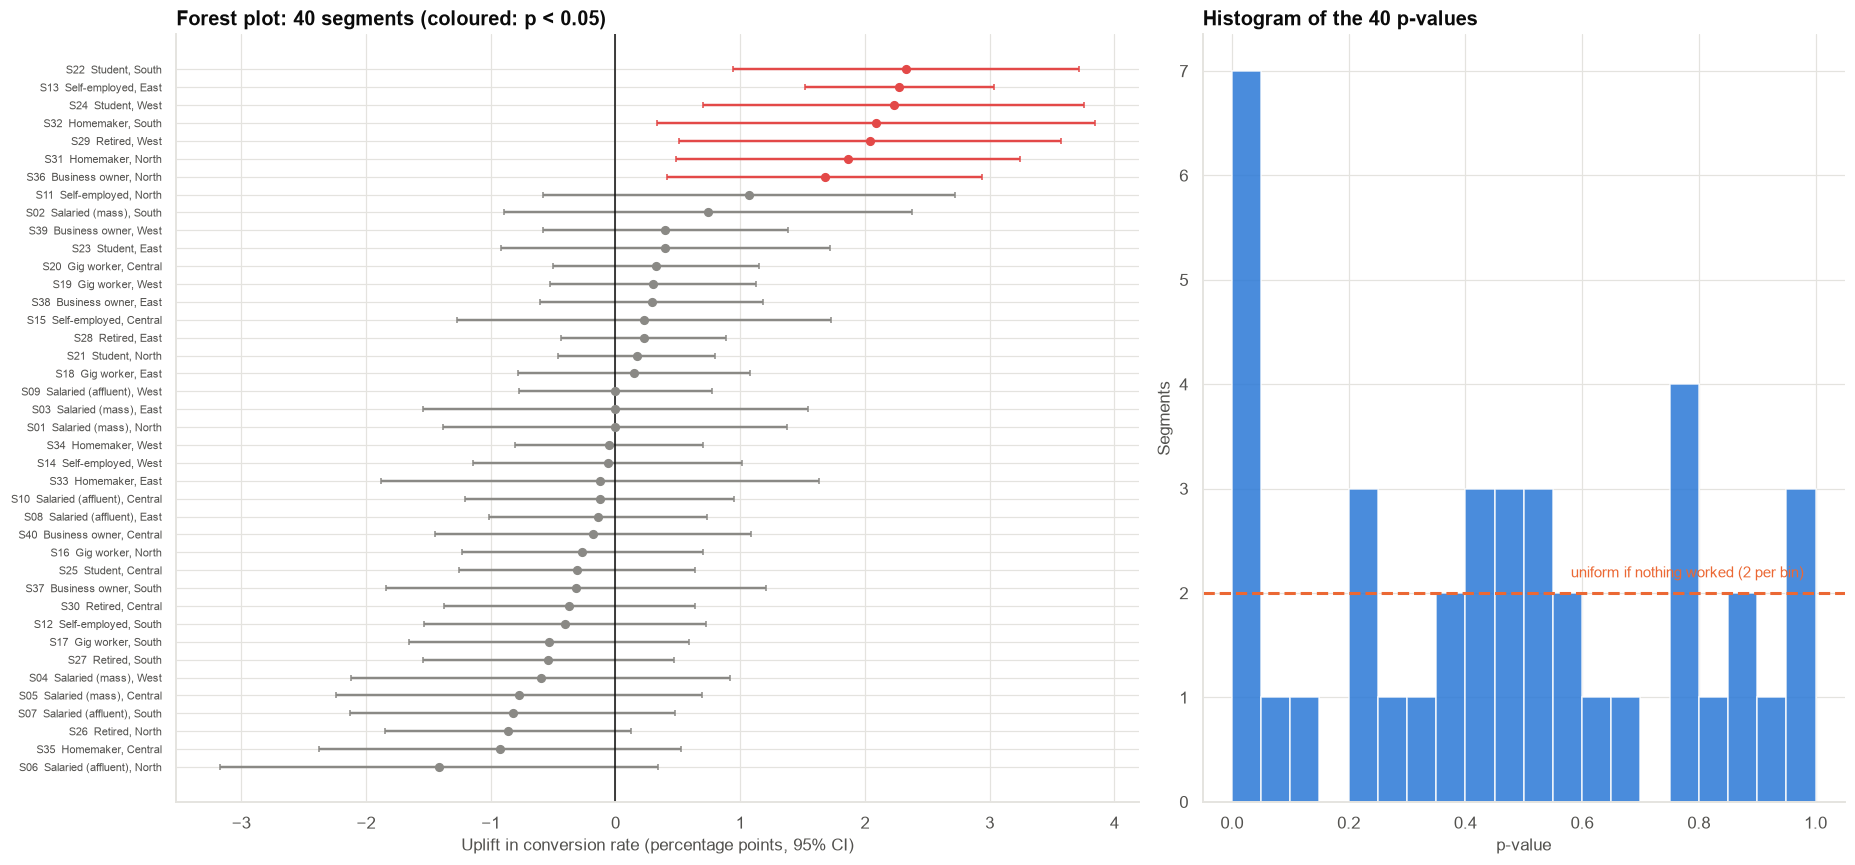

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
rs = res.sort_values("uplift (pp)")
cols = [COLORS["red"] if (r_["significant at 5%"] and r_["uplift (pp)"] > 0) else (COLORS["orange"] if r_["significant at 5%"] else INK_MUTED) for _, r_ in rs.iterrows()]
for i, ((sid, r_), c) in enumerate(zip(rs.iterrows(), cols)):
    ax.errorbar(r_["uplift (pp)"], i, xerr=[[r_["uplift (pp)"] - r_["ci_low (pp)"]], [r_["ci_high (pp)"] - r_["uplift (pp)"]]], fmt="o", color=c, ms=5, lw=1.6, capsize=2)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(range(len(rs)), [f"{sid}  {r_['customer_type']}, {r_['region']}" for sid, r_ in rs.iterrows()], fontsize=7.5)
ax.set(xlabel="Uplift in conversion rate (percentage points, 95% CI)", title="Forest plot: 40 segments (coloured: p < 0.05)")
ax = axes[1]
ax.hist(res["p_value"], bins=np.linspace(0, 1, 21), color=PRIMARY, alpha=0.85, edgecolor="white")
ax.axhline(len(res) / 20, color=HIGHLIGHT, ls="--", lw=2)
ax.text(0.98, len(res) / 20 + 0.15, "uniform if nothing worked (2 per bin)", ha="right", color=HIGHLIGHT, fontsize=10)
ax.set(xlabel="p-value", ylabel="Segments", title="Histogram of the 40 p-values")
fig.tight_layout()
save_fig(fig, "fig01_forest_and_pvalues", PATHS["figures"])
plt.show()

**Observation.** Seven of the 40 segments have p < 0.05, so Marketing's list has seven winners. Pooled over all
segments (one test), the SMS gives a small uplift of about **+0.22 percentage points** (95% CI +0.04 to +0.40, p = 0.017):
real on average but modest, and far smaller than the +1.7 to +2.3 points the seven winners show. The **p-value
histogram** has a spike at the left (small p-values) on top of a roughly flat background.

**Interpretation of the histogram.** If **no** segment responded, the 40 p-values would be spread **evenly** between 0
and 1 (about 2 per bar). A spike near zero means **some** segments really respond; the flat remainder suggests
many segments do not. The p-value histogram is the first diagnostic to draw before any correction.

,P(at least one false alarm),average number of false alarms,"worst case in 5,000 trials"
no correction,0.8724,1.9970,7
Bonferroni,0.0490,0.0494,2
Holm,0.0490,0.0494,2
Benjamini-Hochberg,0.0500,0.0546,3


Theory for 40 independent tests at 5%: P(≥1) = 87.1%, expected = 2.0


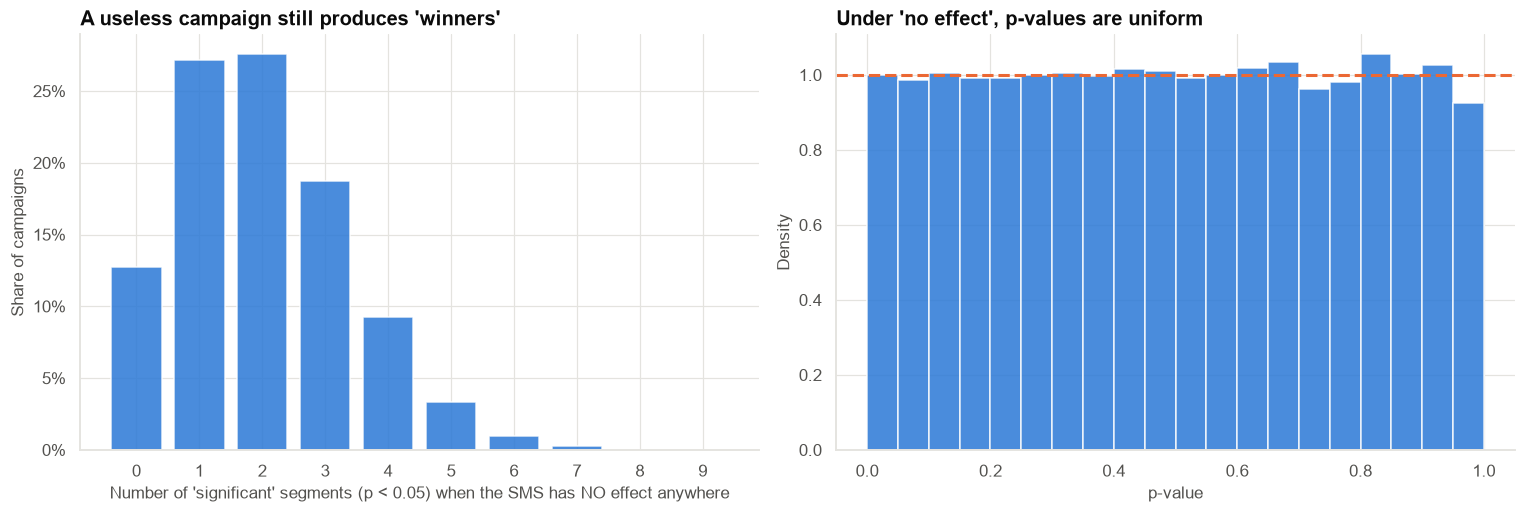

In [5]:
agg = raw.groupby(["segment_id", "arm"])[["customers", "conversions"]].sum().unstack("arm")
n1 = agg[("customers", "treatment")].to_numpy(); n0 = agg[("customers", "control")].to_numpy()
p_null = ((agg[("conversions", "treatment")] + agg[("conversions", "control")]) / (n1 + n0)).to_numpy()   # one common rate per segment
R = 5000
x1 = rng.binomial(n1, p_null, size=(R, len(n1)))
x0 = rng.binomial(n0, p_null, size=(R, len(n0)))
P = two_prop(x1, n1, x0, n0)["p_value"]                       # R × 40 p-values under the null
n_sig = (P < ALPHA).sum(axis=1)

def reject_counts(P, method):
    return np.array([multipletests(row, alpha=ALPHA, method=method)[0].sum() for row in P])

null_sim = pd.DataFrame({
    "no correction": n_sig, "Bonferroni": reject_counts(P, "bonferroni"), "Holm": reject_counts(P, "holm"), "Benjamini-Hochberg": reject_counts(P, "fdr_bh")})
null_tbl = pd.DataFrame({"P(at least one false alarm)": (null_sim > 0).mean(), "average number of false alarms": null_sim.mean(), "worst case in 5,000 trials": null_sim.max()})
save_table(null_tbl, "all_null_simulation", PATHS["tables"])
display(null_tbl)
print(f"Theory for 40 independent tests at 5%: P(≥1) = {1 - 0.95 ** 40:.1%}, expected = 2.0")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
cnt = np.bincount(n_sig, minlength=10)[:10] / R
ax.bar(range(10), cnt, color=PRIMARY, alpha=0.85)
ax.set_xticks(range(10)); ax.yaxis.set_major_formatter(pctfmt)
ax.set(xlabel="Number of 'significant' segments (p < 0.05) when the SMS has NO effect anywhere", ylabel="Share of campaigns",
       title="A useless campaign still produces 'winners'")
ax = axes[1]
ax.hist(P.ravel(), bins=np.linspace(0, 1, 21), color=PRIMARY, alpha=0.85, edgecolor="white", density=True)
ax.axhline(1, color=HIGHLIGHT, ls="--", lw=2)
ax.set(xlabel="p-value", ylabel="Density", title="Under 'no effect', p-values are uniform")
fig.tight_layout()
save_fig(fig, "fig02_all_null_simulation", PATHS["figures"])
plt.show()

**Observation.** In a world where the SMS does **nothing** anywhere, an uncorrected "p < 0.05" screen of 40 segments
still flags **about two** segments on average (1.997 in 5,000 simulated campaigns), and at least one in about **87%** of campaigns, in line with the
formulas. Bonferroni, Holm and Benjamini-Hochberg reduce the chance of any false alarm to about 5% or below.

**Interpretation.** "Significant at 5%" has a **different meaning** when you look at many segments and pick the
significant ones. The **selection** is the problem: each p-value is correct on its own, but the circled ones are the
survivors of a screening of 40.

## Section 8 — Applying the corrections to the real data

,segments declared winners
uncorrected p < 0.05,7
Bonferroni,2
Holm,2
BH (FDR 5%),2
BH (FDR 10%),6


,p_value,Bonferroni-adjusted p,Holm-adjusted p,BH q-value,uplift (pp),uncorrected p < 0.05,Bonferroni,Holm,BH (FDR 5%)
segment_id,,,,,,,,,
S13,0.0000,0.0000,0.0000,0.0000,2.2765,True,True,True,True
S22,0.0010,0.0403,0.0393,0.0202,2.3304,True,True,True,True
S24,0.0043,0.1704,0.1618,0.0568,2.2289,True,False,False,False
S31,0.0080,0.3219,0.2978,0.0614,1.8662,True,False,False,False
S29,0.0091,0.3649,0.3284,0.0614,2.0396,True,False,False,False
S36,0.0092,0.3683,0.3284,0.0614,1.6792,True,False,False,False
S32,0.0198,0.7917,0.6730,0.1131,2.0906,True,False,False,False


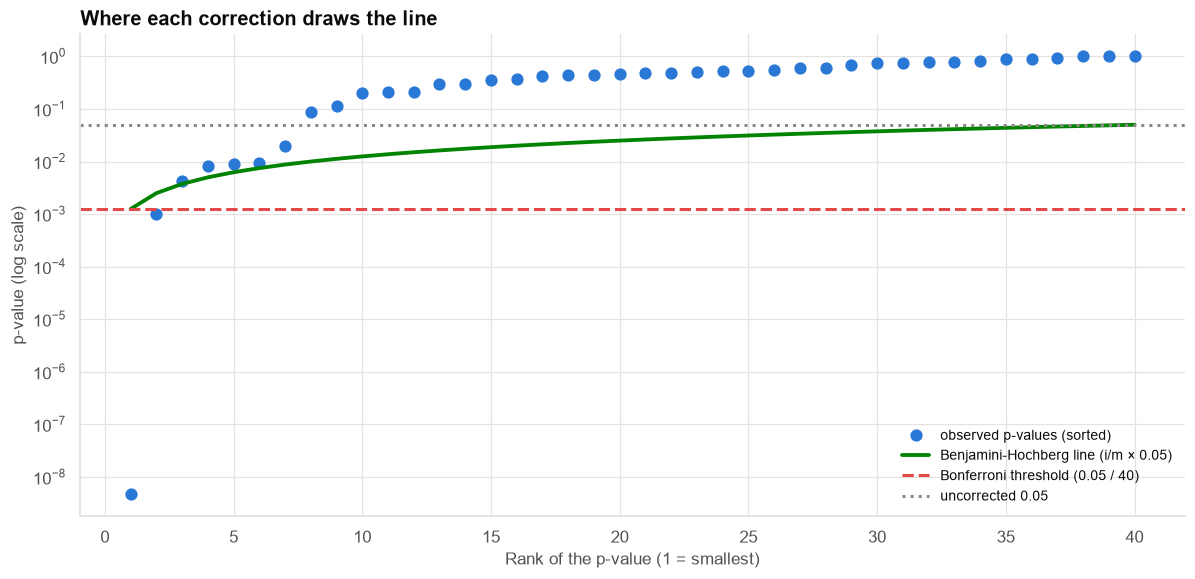

In [6]:
p = res["p_value"].to_numpy()
adj = pd.DataFrame({"p_value": p,
                    "Bonferroni-adjusted p": multipletests(p, method="bonferroni")[1],
                    "Holm-adjusted p": multipletests(p, method="holm")[1],
                    "BH q-value": multipletests(p, method="fdr_bh")[1]}, index=res.index)
adj["uplift (pp)"] = res["uplift (pp)"]
for c_, lab in [("p_value", "uncorrected p < 0.05"), ("Bonferroni-adjusted p", "Bonferroni"), ("Holm-adjusted p", "Holm"), ("BH q-value", "BH (FDR 5%)")]:
    adj[lab] = adj[c_] < ALPHA
adj["BH (FDR 10%)"] = adj["BH q-value"] < 0.10
save_table(adj.join(seg_info), "multiplicity_adjusted", PATHS["tables"])
counts = adj[["uncorrected p < 0.05", "Bonferroni", "Holm", "BH (FDR 5%)", "BH (FDR 10%)"]].sum().rename("segments declared winners").to_frame()
display(counts)
display(adj[adj["uncorrected p < 0.05"] | adj["BH (FDR 5%)"]].drop(columns=["BH (FDR 10%)"]).head(14))

fig, ax = plt.subplots(figsize=(11, 5.4))
ranked = np.sort(p); i_ = np.arange(1, len(p) + 1)
ax.plot(i_, ranked, "o", color=PRIMARY, ms=7, label="observed p-values (sorted)")
ax.plot(i_, ALPHA * i_ / len(p), "-", color=COLORS["green"], lw=2.5, label="Benjamini-Hochberg line (i/m × 0.05)")
ax.axhline(ALPHA / len(p), color=COLORS["red"], ls="--", lw=2, label="Bonferroni threshold (0.05 / 40)")
ax.axhline(ALPHA, color=INK_MUTED, ls=":", lw=2, label="uncorrected 0.05")
ax.set_yscale("log")
ax.set(xlabel="Rank of the p-value (1 = smallest)", ylabel="p-value (log scale)", title="Where each correction draws the line")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig03_correction_lines", PATHS["figures"])
plt.show()

**Observation.** Of the seven uncorrected winners, only **two** (S13 and S22) survive Bonferroni and Holm.
**Benjamini-Hochberg** at a 5% FDR also keeps just those two; at a 10% FDR it keeps **six** (the other four have q-values
of 0.057 to 0.061, just above 5%).

**Interpretation.**
- **Bonferroni / Holm** protect against *any* false alarm, but at this sample size they discard most real responders
  (low power).
- **BH** accepts that a small share of the declared winners (≤ the chosen FDR, on average) may be false. At 5% it
  is no more generous than Holm here, so the choice between them matters only in the 5–10% zone. Where being wrong about one segment costs a
  little wasted SMS spend, a 10% FDR is a defensible choice for a *promising* list, provided it is confirmed afterwards.
- **Holm is never worse than Bonferroni**, so there is no reason to use plain Bonferroni.

**What the adjusted values mean.** A **q-value** of 0.06 says: if you declare everything with q ≤ 0.06 a discovery,
about 6% of those discoveries are expected to be false. A **Holm-adjusted p** of 0.03 can be compared with 0.05 as if
it were an ordinary p-value, with the family-wise error controlled.

## Section 9 — The winner's curse: do the winners keep winning?

The campaign ran in **two waves**. We use **wave 1 as a discovery sample**: pick the segments with p < 0.05 in wave 1
alone, then look at **wave 2**, which these choices have not seen.

,segments,average estimated uplift (pp),still significant (p < 0.05)
wave 1 (where they were selected),6,2.3852,6
"wave 2 (fresh data, same segments)",6,0.8843,1


All 40 segments: correlation of wave-1 and wave-2 uplift r = 0.31; regression slope = 0.25 (1 would mean no shrinkage)


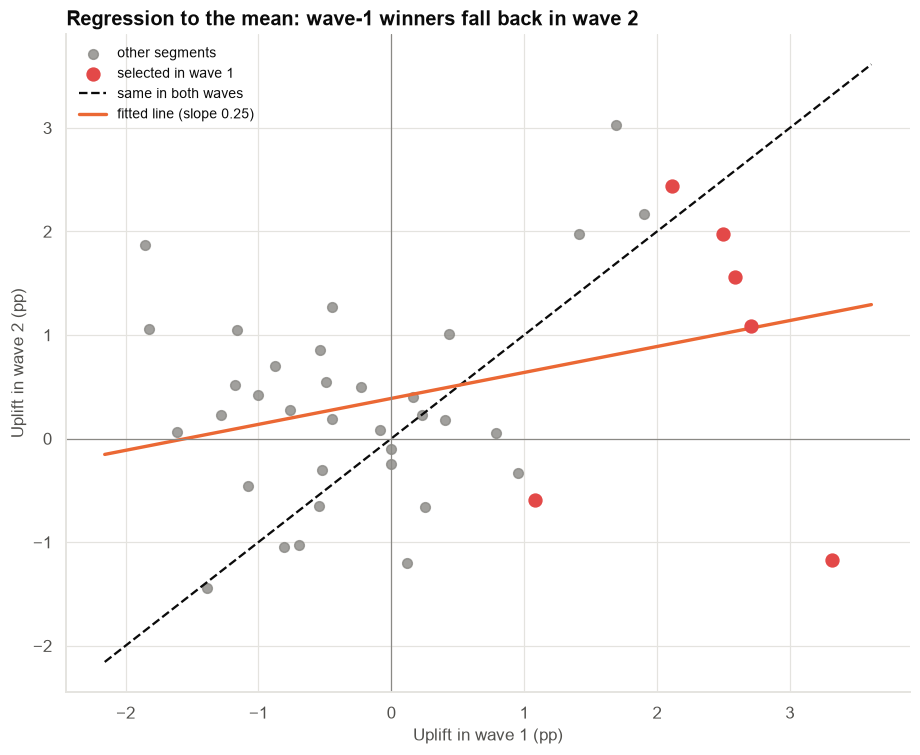

In [7]:
w1 = seg_table(raw[raw["wave"] == 1]); w2 = seg_table(raw[raw["wave"] == 2])
cmp = pd.DataFrame({"uplift wave 1 (pp)": w1["uplift (pp)"], "p wave 1": w1["p_value"], "uplift wave 2 (pp)": w2["uplift (pp)"], "p wave 2": w2["p_value"]})
cmp["selected in wave 1 (p < 0.05, positive)"] = (cmp["p wave 1"] < ALPHA) & (cmp["uplift wave 1 (pp)"] > 0)
sel = cmp[cmp["selected in wave 1 (p < 0.05, positive)"]]
summ = pd.DataFrame({"segments": [len(sel), len(sel)],
                     "average estimated uplift (pp)": [sel["uplift wave 1 (pp)"].mean(), sel["uplift wave 2 (pp)"].mean()],
                     "still significant (p < 0.05)": [len(sel), int((sel["p wave 2"] < ALPHA).sum())]},
                    index=["wave 1 (where they were selected)", "wave 2 (fresh data, same segments)"])
save_table(summ, "winners_curse_two_waves", PATHS["tables"])
save_table(cmp, "wave1_vs_wave2", PATHS["tables"])
display(summ)
slope = stats.linregress(cmp["uplift wave 1 (pp)"], cmp["uplift wave 2 (pp)"])
print(f"All 40 segments: correlation of wave-1 and wave-2 uplift r = {slope.rvalue:.2f}; regression slope = {slope.slope:.2f} (1 would mean no shrinkage)")

fig, ax = plt.subplots(figsize=(8.5, 7))
nonsel = cmp[~cmp["selected in wave 1 (p < 0.05, positive)"]]
ax.scatter(nonsel["uplift wave 1 (pp)"], nonsel["uplift wave 2 (pp)"], s=40, color=INK_MUTED, alpha=0.8, label="other segments")
ax.scatter(sel["uplift wave 1 (pp)"], sel["uplift wave 2 (pp)"], s=70, color=COLORS["red"], label="selected in wave 1", zorder=3)
lims = [min(cmp.iloc[:, [0, 2]].min()) - 0.3, max(cmp.iloc[:, [0, 2]].max()) + 0.3]
ax.plot(lims, lims, color=INK, ls="--", lw=1.5, label="same in both waves")
xs = np.array(lims); ax.plot(xs, slope.intercept + slope.slope * xs, color=HIGHLIGHT, lw=2.2, label=f"fitted line (slope {slope.slope:.2f})")
ax.axhline(0, color=INK_MUTED, lw=0.8); ax.axvline(0, color=INK_MUTED, lw=0.8)
ax.set(xlabel="Uplift in wave 1 (pp)", ylabel="Uplift in wave 2 (pp)", title="Regression to the mean: wave-1 winners fall back in wave 2")
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
save_fig(fig, "fig04_winners_curse", PATHS["figures"])
plt.show()

**Observation.** The six segments selected as winners in wave 1 had an average estimated uplift of **+2.39 points**.
In wave 2, the same segments show **+0.88 points**, and only **one of the six** is still individually significant. Across
all segments, wave-2 uplift is only weakly predicted by wave-1 uplift (r = 0.31, slope 0.25: a strongly **shrunken**
version).

**Interpretation: the winner's curse.** When you pick the segments with the largest estimated effects, you select
partly for **real** effects and partly for **lucky noise**. The luckiest segments look best, so their estimated
effect is **too big**. In fresh data the luck does not repeat, and the estimate falls back (**regression to the
mean**). The same logic means the uplift for the seven uncorrected winners in the pooled data is overstated too.

**A replication wave is the cleanest remedy**: a segment that wins twice, in independent data, is far more credible
than one that wins once.

### 9.1 Shrinkage: an empirical-Bayes correction

In [8]:
est = res["uplift (pp)"]; se = res["se (pp)"]
grand = est.mean()
tau2 = max(0.0, est.var() - (se ** 2).mean())
B = tau2 / (tau2 + se ** 2)
res["shrunken uplift (pp)"] = grand + B * (est - grand)
res["shrinkage factor B"] = B
print(f"Spread of estimates: variance {est.var():.3f};  average sampling variance {(se ** 2).mean():.3f};  estimated true-effect variance τ² = {tau2:.3f}")
print(f"Shrinkage factors range {B.min():.2f}–{B.max():.2f} (1 = no shrinkage, 0 = replace the estimate by the overall average)")
shr = res[["customer_type", "region", "uplift (pp)", "shrunken uplift (pp)", "shrinkage factor B", "p_value"]].head(10)
save_table(res[["uplift (pp)", "shrunken uplift (pp)", "shrinkage factor B", "p_value"]], "shrinkage_estimates", PATHS["tables"])
shr

Spread of estimates: variance 0.944;  average sampling variance 0.405;  estimated true-effect variance τ² = 0.539
Shrinkage factors range 0.40–0.84 (1 = no shrinkage, 0 = replace the estimate by the overall average)


,customer_type,region,uplift (pp),shrunken uplift (pp),shrinkage factor B,p_value
segment_id,,,,,,
S13,Self-employed,East,2.2765,1.8343,0.7818,0.0000
S22,Student,South,2.3304,1.3282,0.5182,0.0010
S24,Student,West,2.2289,1.1815,0.4707,0.0043
S31,Homemaker,North,1.8662,1.0926,0.5213,0.0080
S29,Retired,West,2.0396,1.0894,0.4691,0.0091
S36,Business owner,North,1.6792,1.0576,0.5651,0.0092
S32,Homemaker,South,2.0906,0.9893,0.4016,0.0198
S26,Retired,North,-0.8614,-0.5077,0.6817,0.0861
S06,Salaried (affluent),North,-1.4134,-0.4185,0.4019,0.1148


**Observation.** The shrinkage pulls extreme estimates towards the overall mean (estimated true-effect variance
τ² = 0.54 against an average sampling variance of 0.41), by factors between 0.40 and 0.84: the most for the segments with
**noisy** estimates (small segments). S32, for example, goes from +2.09 to +0.99.

**Interpretation.** **Empirical-Bayes shrinkage** estimates how much of the spread among segment estimates is real
(τ²) and how much is sampling noise, and shrinks each estimate accordingly. It does not decide which segments are
significant; it gives **better estimates of size** for planning (expected incremental conversions).

**Caveat.** This simple normal-normal version assumes the true effects are drawn from one normal distribution. Here
most segments have no effect and a few have large ones (a **spike-and-slab** mixture), so the simple shrinkage is
imperfect: it shrinks the real responders too much and the non-responders too little. We check it against the truth
below.

## Section 10 — How much power does each segment have?

Per segment there are about 1,500–4,700 customers per arm over two waves. The **minimum detectable effect** (MDE,
Case 04) at 80% power and α = 0.05 for a segment with baseline rate p and n per arm is about
2.8 × √(2 p (1 − p) / n). With a **Bonferroni** α of 0.05/40, the MDE is larger still.

In [9]:
n_arm = res["customers per arm"]
p0 = res["control rate"]
def mde(alpha_):
    z_a, z_b = stats.norm.isf(alpha_ / 2), stats.norm.isf(0.2)
    return 100 * (z_a + z_b) * np.sqrt(2 * p0 * (1 - p0) / n_arm)
pw = pd.DataFrame({"customers per arm": n_arm, "control rate": p0, "MDE at α = 0.05 (pp)": mde(ALPHA), "MDE at α = 0.05/40 (pp)": mde(ALPHA / 40)})
save_table(pw, "segment_mde", PATHS["tables"])
print(f"Median MDE over the 40 segments: {pw['MDE at α = 0.05 (pp)'].median():.2f} pp at α = 0.05;  {pw['MDE at α = 0.05/40 (pp)'].median():.2f} pp with the Bonferroni α")
pw.describe().loc[["min", "50%", "max"]]

Median MDE over the 40 segments: 1.65 pp at α = 0.05;  2.39 pp with the Bonferroni α


,customers per arm,control rate,MDE at α = 0.05 (pp),MDE at α = 0.05/40 (pp)
min,"1,480.0000",0.0193,0.8860,1.2868
50%,"2,883.5000",0.0512,1.6452,2.3893
max,"4,693.0000",0.0915,2.6186,3.8031


**Observation.** A typical segment can reliably detect an uplift of about **1.65 points** at the usual α, and about
**2.4 points** with the Bonferroni α (range 0.9 to 2.6, and 1.3 to 3.8). The pooled campaign uplift (+0.22 points) and
most true segment uplifts are **smaller** than that.

**Interpretation.** Segment-level tests are **underpowered** for modest effects, and multiple-testing corrections
reduce power further. "Not significant" in a segment means "**no evidence**", not "no effect", and Bonferroni's
losses are mainly **missed real winners**.

## Section 11 — Grading the methods (using the answer key)

Because the data are simulated, we can open the answer key, which lists the true uplift of every segment (8 truly
positive, 3 truly negative, 29 with no effect at all).

In [10]:
key = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv").set_index("segment_id")
adj2 = adj.join(key)
adj2["truth"] = np.select([adj2["true_uplift_pp"] > 0, adj2["true_uplift_pp"] < 0], ["real positive effect (8)", "real negative effect (3)"], default="no effect (29)")
rows = []
for m_ in ["uncorrected p < 0.05", "Bonferroni", "Holm", "BH (FDR 5%)", "BH (FDR 10%)"]:
    flagged = adj2[adj2[m_]]
    pos = flagged[flagged["uplift (pp)"] > 0]
    rows.append({"method": m_, "declared winners": len(pos),
                 "truly positive (correct)": int((pos["true_uplift_pp"] > 0).sum()), "no real effect (false alarm)": int((pos["true_uplift_pp"] == 0).sum()),
                 "truly harmful (wrong sign)": int((pos["true_uplift_pp"] < 0).sum()),
                 "also flagged as significant LOSERS": int((flagged["uplift (pp)"] < 0).sum()),
                 "real winners found (of 8)": int((pos["true_uplift_pp"] > 0).sum())})
grade = pd.DataFrame(rows).set_index("method")
grade["false discovery proportion"] = (grade["no real effect (false alarm)"] + grade["truly harmful (wrong sign)"]) / grade["declared winners"].replace(0, np.nan)
save_table(grade, "method_grading", PATHS["tables"])
display(grade)
# Estimation accuracy
sel_unc = adj2[adj2["uncorrected p < 0.05"] & (adj2["uplift (pp)"] > 0)]
print(f"\nUncorrected winners: average estimated uplift {sel_unc['uplift (pp)'].mean():.2f} pp vs average TRUE uplift {sel_unc['true_uplift_pp'].mean():.2f} pp  (winner's curse)")
res_k = res.join(key)
for nm, col in [("raw estimate", "uplift (pp)"), ("empirical-Bayes shrunken", "shrunken uplift (pp)")]:
    err = res_k[col] - res_k["true_uplift_pp"]
    top = res_k.sort_values("p_value").head(9)
    print(f"{nm:>26}: RMSE over all 40 segments {np.sqrt((err ** 2).mean()):.2f} pp;  mean error among the 9 smallest p-values {(top[col] - top['true_uplift_pp']).mean():+.2f} pp")

,declared winners,truly positive (correct),no real effect (false alarm),truly harmful (wrong sign),also flagged as significant LOSERS,real winners found (of 8),false discovery proportion
method,,,,,,,
uncorrected p < 0.05,7,5,2,0,0,5,0.2857
Bonferroni,2,2,0,0,0,2,0.0000
Holm,2,2,0,0,0,2,0.0000
BH (FDR 5%),2,2,0,0,0,2,0.0000
BH (FDR 10%),6,4,2,0,0,4,0.3333



Uncorrected winners: average estimated uplift 2.07 pp vs average TRUE uplift 1.43 pp  (winner's curse)
              raw estimate: RMSE over all 40 segments 0.75 pp;  mean error among the 9 smallest p-values +0.34 pp
  empirical-Bayes shrunken: RMSE over all 40 segments 0.62 pp;  mean error among the 9 smallest p-values -0.17 pp


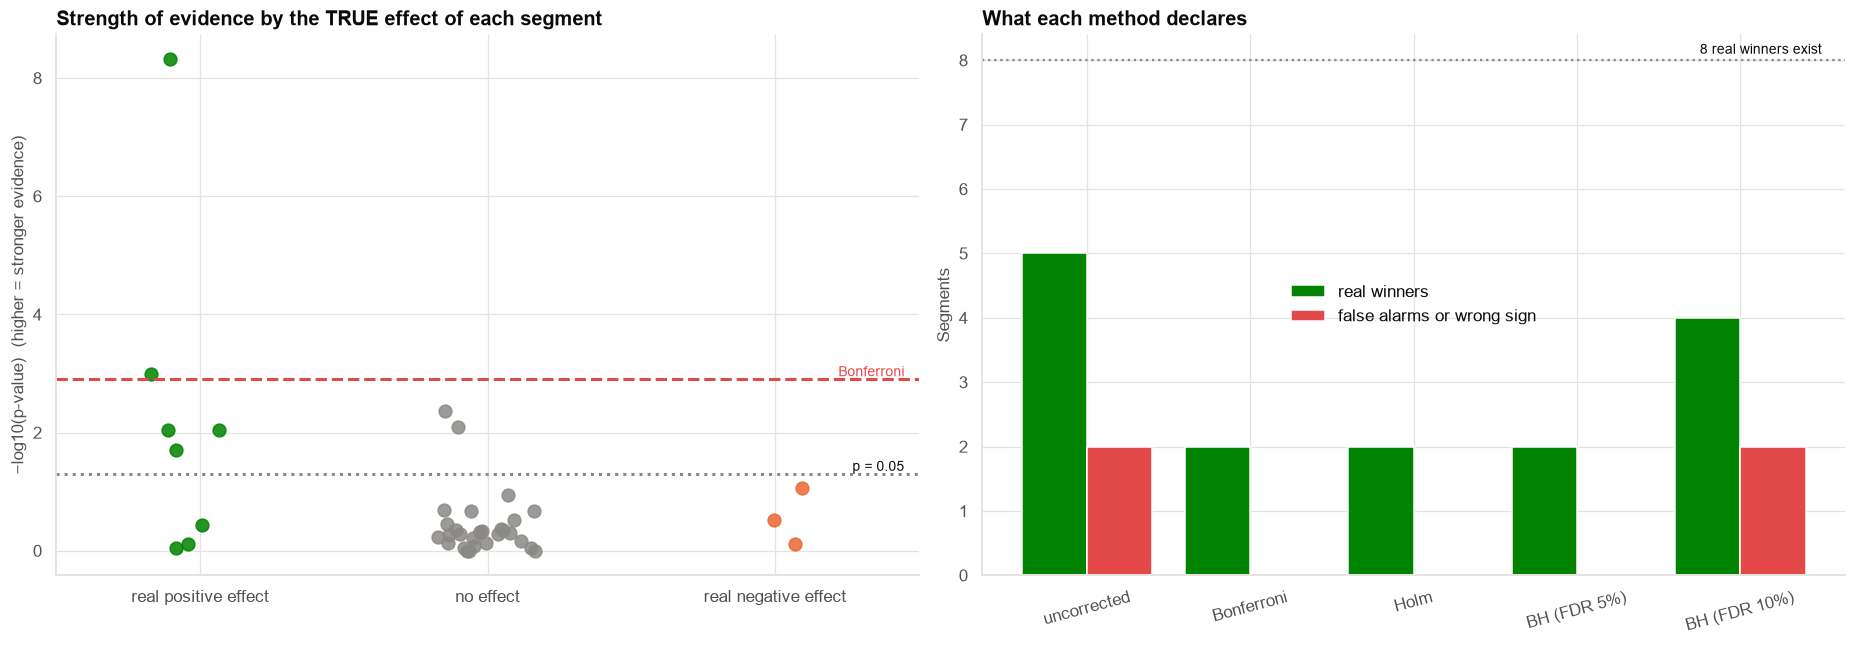

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
ax = axes[0]
order_t = ["real positive effect (8)", "no effect (29)", "real negative effect (3)"]
tcol = {"real positive effect (8)": COLORS["green"], "no effect (29)": INK_MUTED, "real negative effect (3)": COLORS["orange"]}
for i, t_ in enumerate(order_t):
    sub = adj2[adj2["truth"] == t_]
    ax.scatter(np.full(len(sub), i) + rng.uniform(-0.18, 0.18, len(sub)), -np.log10(sub["p_value"]), s=70, color=tcol[t_], alpha=0.85)
ax.axhline(-np.log10(ALPHA), color=INK_MUTED, ls=":", lw=2); ax.text(2.45, -np.log10(ALPHA) + 0.05, "p = 0.05", ha="right", fontsize=9)
ax.axhline(-np.log10(ALPHA / 40), color=COLORS["red"], ls="--", lw=2); ax.text(2.45, -np.log10(ALPHA / 40) + 0.05, "Bonferroni", ha="right", fontsize=9, color=COLORS["red"])
ax.set_xticks(range(3), [t.split(" (")[0] for t in order_t]); ax.set_xlim(-0.5, 2.5)
ax.set(ylabel="−log10(p-value)  (higher = stronger evidence)", title="Strength of evidence by the TRUE effect of each segment")
ax = axes[1]
x = np.arange(len(grade))
ax.bar(x - 0.2, grade["truly positive (correct)"], width=0.4, color=COLORS["green"], label="real winners")
ax.bar(x + 0.2, grade["no real effect (false alarm)"] + grade["truly harmful (wrong sign)"], width=0.4, color=COLORS["red"], label="false alarms or wrong sign")
ax.set_xticks(x, [m.replace("uncorrected p < 0.05", "uncorrected") for m in grade.index], rotation=15)
ax.axhline(8, color=INK_MUTED, ls=":"); ax.text(len(grade) - 0.5, 8.1, "8 real winners exist", ha="right", fontsize=9)
ax.set(ylabel="Segments", title="What each method declares"); ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "fig05_grading", PATHS["figures"])
plt.show()

**Observation.**

| Method | Declared winners | Real | False alarms | Real winners found (of 8) |
|---|---|---|---|---|
| Uncorrected p < 0.05 | 7 | 5 | 2 (29% of the list) | 5 |
| Bonferroni / Holm / BH 5% | 2 | 2 | 0 | 2 |
| BH at 10% | 6 | 4 | 2 (33% of the list) | 4 |

- The uncorrected list is **29% false**, in line with the warning, but not a disaster; the real cost is *calibration*,
  see below.
- Every corrected method has no false alarm at 5%, but **finds only 2 of the 8 real winners**: low power, not a flaw.
- At a 10% FDR the declared list has two false alarms in six, which is 33% on this one run, above the nominal 10%.
  With 6 discoveries a single run is very noisy: FDR is a **long-run average**, not a guarantee for one list.
- **Winner's curse is visible:** the uncorrected winners' estimated uplift averages 2.07 points against a true 1.43.
  Empirical-Bayes shrinkage cuts the overall error (RMSE 0.75 → 0.62 points) and removes the upward bias among the
  most significant segments (+0.34 → −0.17), slightly over-correcting.

In [12]:
t = res.join(adj[["BH q-value", "Holm-adjusted p"]])
conf = (t["Holm-adjusted p"] < ALPHA) & (t["uplift (pp)"] > 0)
prom = (t["BH q-value"] < 0.10) & (t["uplift (pp)"] > 0) & ~conf
t["tier"] = np.select([conf, prom, t["uplift (pp)"] < 0], ["1. Confirmed (survives Holm, FWER 5%)", "2. Promising (BH q < 0.10): confirm in wave 3", "4. Negative or none: do not target"],
                      default="3. Not supported by the data: default campaign")
tier_tbl = t.groupby("tier").agg(segments=("uplift (pp)", "size"), customers_per_arm=("customers per arm", "sum"),
                                 mean_uplift_pp=("uplift (pp)", "mean"), mean_shrunken_pp=("shrunken uplift (pp)", "mean"))
save_table(tier_tbl, "tiers", PATHS["tables"])
display(tier_tbl)
display(t[t["tier"].str.startswith(("1", "2"))][["customer_type", "region", "uplift (pp)", "shrunken uplift (pp)", "ci_low (pp)", "ci_high (pp)", "p_value", "BH q-value", "Holm-adjusted p", "tier"]])

,segments,customers_per_arm,mean_uplift_pp,mean_shrunken_pp
tier,,,,
"1. Confirmed (survives Holm, FWER 5%)",2,"7,607.0000",2.3034,1.5812
2. Promising (BH q < 0.10): confirm in wave 3,4,"8,381.0000",1.9535,1.1053
3. Not supported by the data: default campaign,15,"46,950.0000",0.4262,0.3172
4. Negative or none: do not target,19,"56,099.0000",-0.4637,-0.1557


,customer_type,region,uplift (pp),shrunken uplift (pp),ci_low (pp),ci_high (pp),p_value,BH q-value,Holm-adjusted p,tier
segment_id,,,,,,,,,,
S13,Self-employed,East,2.2765,1.8343,1.5160,3.0370,0.0000,0.0000,0.0000,"1. Confirmed (survives Holm, FWER 5%)"
S22,Student,South,2.3304,1.3282,0.9425,3.7183,0.0010,0.0202,0.0393,"1. Confirmed (survives Holm, FWER 5%)"
S24,Student,West,2.2289,1.1815,0.7024,3.7554,0.0043,0.0568,0.1618,2. Promising (BH q < 0.10): confirm in wave 3
S31,Homemaker,North,1.8662,1.0926,0.4868,3.2456,0.0080,0.0614,0.2978,2. Promising (BH q < 0.10): confirm in wave 3
S29,Retired,West,2.0396,1.0894,0.5081,3.5711,0.0091,0.0614,0.3284,2. Promising (BH q < 0.10): confirm in wave 3
S36,Business owner,North,1.6792,1.0576,0.4163,2.9420,0.0092,0.0614,0.3284,2. Promising (BH q < 0.10): confirm in wave 3


**Observation.** Two segments (S13 and S22) are **confirmed** even under the strictest correction; four more are
**promising** (q < 0.10) and should be re-tested; 15 have no reliable evidence of a response, and 19 show a negative or zero estimate, which with these
sample sizes is not evidence of harm. Budget with the shrunken uplift (about +1.6 for confirmed, +1.1 for promising).

| Situation | Do this |
|---|---|
| You planned **one** primary comparison | Test it at α = 0.05; report the other looks as exploratory |
| **Many** segments / metrics / variants and one false positive is costly | Control **FWER**: Holm (never plain Bonferroni) |
| **Many** looks, discoveries expected, some false ones tolerable (targeting, screening) | Control **FDR**: Benjamini-Hochberg; state the FDR level |
| Tests are **positively correlated** (overlapping segments, correlated metrics) | BH is valid under positive dependence; Bonferroni/Holm remain valid but conservative |
| You need **effect sizes** of the selected winners | Expect inflation: replicate, or shrink (empirical Bayes) |
| You can run a **second wave** | Select in wave 1, confirm in wave 2, and analyse wave 2 for the final size |
| The pooled (overall) effect answers the business question | Test it **once**, before looking at segments |
| Segments were chosen **after** looking at the data | Treat as hypothesis-generating; the number of "forking paths" counts as m |

**Choosing the number m honestly.** m is the number of questions you *could* have asked, not only those reported.
Slicing by 8 customer types, 5 regions and their combinations is one family of 40. Add slicing by age, tenure or
product and the family grows. Decide the family **before** looking at results.

**Never do**
- Report only the significant segments without saying how many were examined.
- Switch to a different correction after seeing which one gives the answer you wanted.
- Present the first-wave effect size of selected winners as the expected effect next quarter.

## Section 14 — Results

In [13]:
summary = pd.DataFrame({"Value": [
    f"{int(res['significant at 5%'].sum())} of 40 at p < 0.05; overall pooled uplift {100 * overall['diff']:+.2f} pp (p {fmt_p(float(overall['p_value']))})",
    f"no effect anywhere: ≥ 1 false alarm in {(null_sim['no correction'] > 0).mean():.0%} of campaigns (avg {null_sim['no correction'].mean():.1f}); Holm {(null_sim['Holm'] > 0).mean():.1%}; BH {(null_sim['Benjamini-Hochberg'] > 0).mean():.1%}",
    f"Bonferroni {int(counts.loc['Bonferroni'].iloc[0])}, Holm {int(counts.loc['Holm'].iloc[0])}, BH 5% {int(counts.loc['BH (FDR 5%)'].iloc[0])}, BH 10% {int(counts.loc['BH (FDR 10%)'].iloc[0])}",
    f"wave 1 {summ.iloc[0, 1]:.2f} pp → wave 2 {summ.iloc[1, 1]:.2f} pp for the {len(sel)} wave-1 winners; {int(summ.iloc[1, 2])} still significant",
    f"median MDE {pw['MDE at α = 0.05 (pp)'].median():.1f} pp (α = 0.05) and {pw['MDE at α = 0.05/40 (pp)'].median():.1f} pp (Bonferroni)",
    "; ".join(f"{k}: {int(grade.loc[k, 'truly positive (correct)'])} real, {int(grade.loc[k, 'no real effect (false alarm)'] + grade.loc[k, 'truly harmful (wrong sign)'])} false" for k in ["uncorrected p < 0.05", "Holm", "BH (FDR 5%)"]),
]}, index=["Marketing's winners", "False-alarm simulation", "Corrections", "Winner's curse (two waves)", "Power", "Grading"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Marketing's winners,7 of 40 at p < 0.05; overall pooled uplift +0....
False-alarm simulation,no effect anywhere: ≥ 1 false alarm in 87% of ...
Corrections,"Bonferroni 2, Holm 2, BH 5% 2, BH 10% 6"
Winner's curse (two waves),wave 1 2.39 pp → wave 2 0.88 pp for the 6 wave...
Power,median MDE 1.6 pp (α = 0.05) and 2.4 pp (Bonfe...
Grading,"uncorrected p < 0.05: 5 real, 2 false; Holm: 2..."


## Section 15 — Interpretation

- **Uncorrected "winners" are partly luck.** Selecting the significant ones from 40 tests guarantees some false
  alarms (about two expected even if nothing works) and inflates the estimated effects (2.07 against a true 1.43).
- **The right correction depends on the cost of a false alarm.** For a confirmed list, FWER control (Holm) is safe but
  finds only 2 of 8 real winners. For a *promising* list, a 10% FDR finds 4 of 8 at the price of some false entries,
  which a confirmation wave then removes.
- **The overall effect is real and small** (+0.22 points, p = 0.017). The SMS works on average; the segment story is much weaker than it looks.
- **Evidence for individual segments is limited by power.** Many "non-significant" segments are simply under-tested.

## Section 16 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "The campaign increases conversion by about 0.2 points overall (95% CI 0.04 to 0.40)." | "Seven segments respond to the campaign." |
| "Two segments are confirmed (survive Holm); four more are promising (BH q < 0.10)." | "The other 34 segments don't respond." (Underpowered.) |
| "Estimated uplifts in selected segments are probably overstated; wave 2 shows about a third of the wave-1 effect." | "Segment S13 will deliver +2.3 points." |
| "A segment with an estimated negative effect is not evidence of harm without a corrected test." | "Segment S26 is harmful." |

## Section 17 — Business interpretation

- **Default:** keep sending the campaign broadly. The overall effect is positive, and nothing in the data justifies
  dropping 34 segments.
- **Targeting:** prioritise the confirmed and promising segments, and **budget with the shrunken uplifts**, not the
  raw ones.
- **Process:** next quarter, **pre-register** the primary analysis (overall effect) and the segment family, and run the
  segment tests as a confirmation wave for the promising list.

## Section 18 — Limitations

- Segments are not independent in real life (customers belong to a type and a region); BH is valid under positive
  dependence, but the exact error rates will differ.
- Two waves only; wave 2 has the same power limits as wave 1.
- A simple normal prior for shrinkage; mixture models fit better.
- One simulated dataset: counts such as "2 of 6 false" are noisy; the all-null simulation shows the long-run behaviour.

## Section 19 — Final recommendation

> **Do not circle the seven uncorrected winners.** Report the **overall uplift** (+0.22 points) as the main finding, a **tiered
> segment list** (2 confirmed, 4 promising, the remainder unsupported), and **shrunken** uplift estimates for
> planning. **Run a confirmation wave** on the promising segments before cutting anyone from the campaign.

## Section 20 — What would I do next?

1. Design the **confirmation wave** with enough customers per promising segment for 80% power at their shrunken
   effect, and analyse it with a pre-specified decision rule.
2. Fit a **hierarchical model** (customer type × region) so that segments borrow strength from each other.
3. Estimate **individual-level uplift** with a causal model (Case 21) instead of 40 separate tests.
4. Make **multiplicity corrections the default** in the experimentation dashboard (e.g. BH q-values next to p-values).
5. Continue to **Case 20** (Simpson's paradox: when the overall comparison reverses within segments).